Dataset Shape: (200000, 9)
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647   

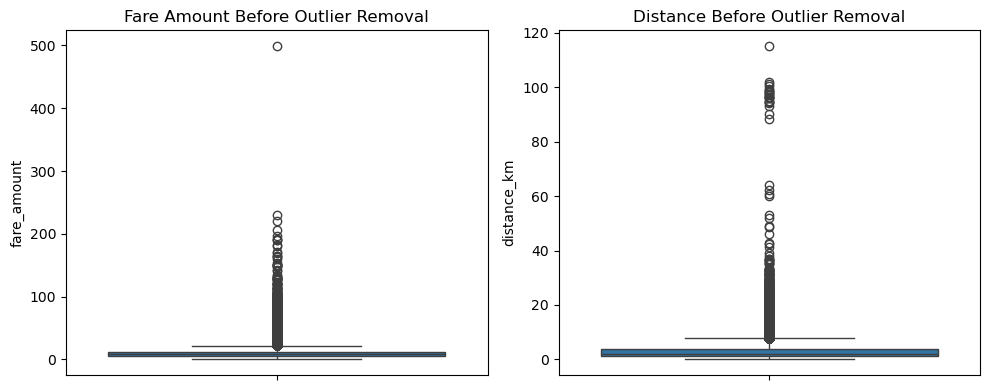


Dataset after outlier removal: (168801, 13)


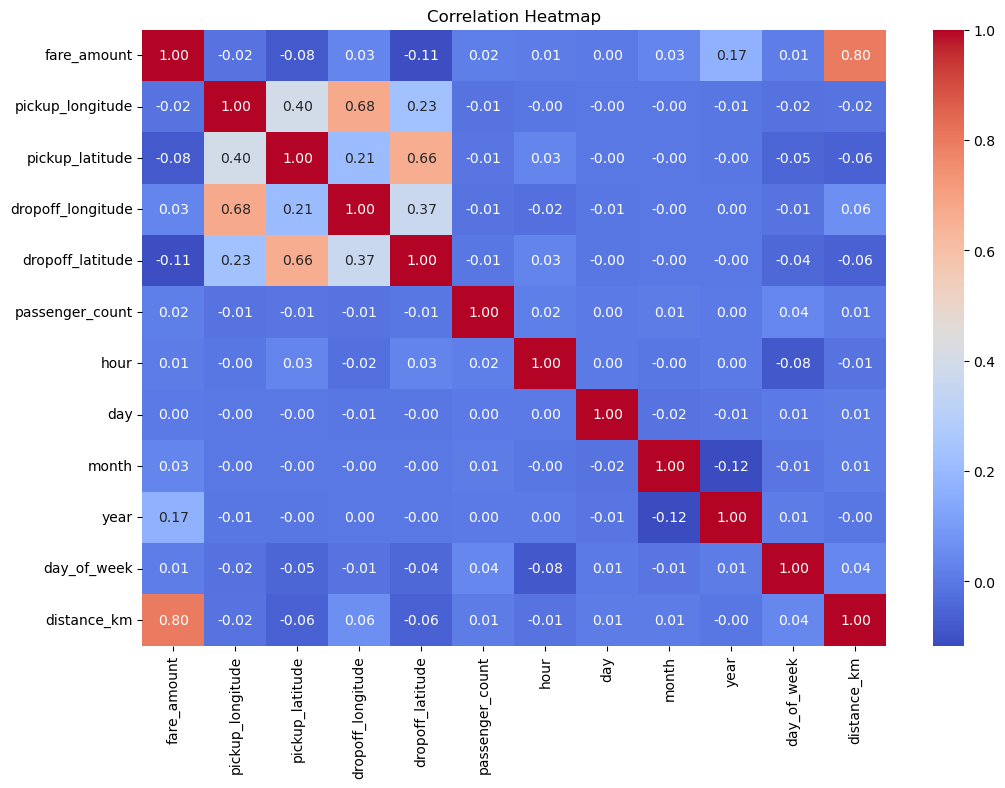


Correlation with Fare Amount:
fare_amount          1.000000
distance_km          0.795088
year                 0.173408
dropoff_longitude    0.034008
month                0.032705
passenger_count      0.016832
day_of_week          0.013102
hour                 0.006843
day                  0.004878
pickup_longitude    -0.015299
pickup_latitude     -0.078051
dropoff_latitude    -0.109348
Name: fare_amount, dtype: float64

Model Performance Comparison:
                   Model  R2 Score     RMSE      MAE
       Linear Regression  0.669463 2.128149 1.515606
Random Forest Regression  0.744268 1.871906 1.296291


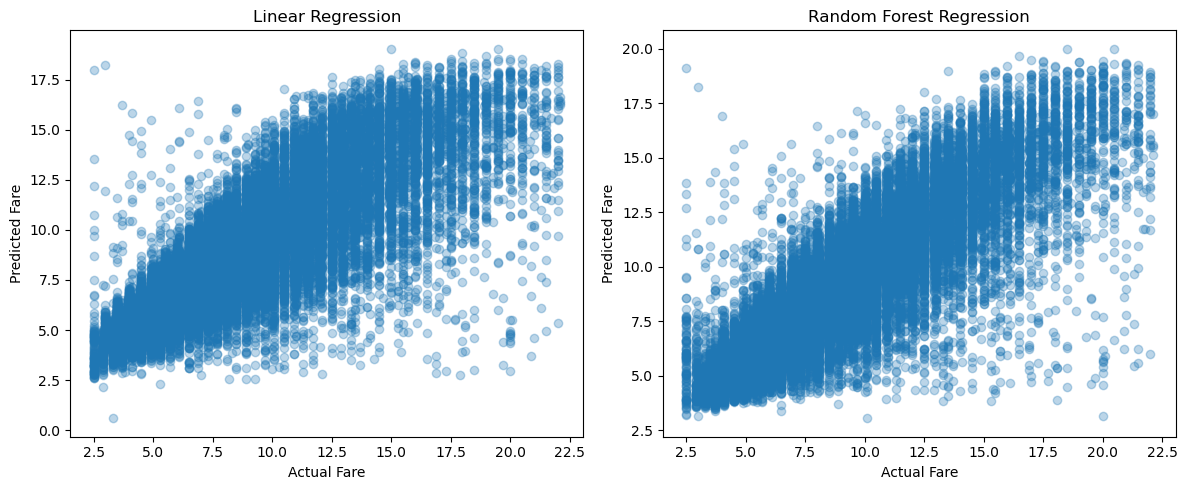

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load Dataset
df = pd.read_csv("uber.csv")

print("Dataset Shape:", df.shape)
print(df.head())

# 2. Data Preprocessing
df.drop(columns=['Unnamed: 0', 'key'], errors='ignore', inplace=True)
df.drop_duplicates(inplace=True)

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)

df.dropna(inplace=True)

# Extract date and time features
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

# Calculate geographical distance using Haversine formula
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin(dlon / 2) ** 2)

    return 6371 * 2 * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

# Remove invalid values
df = df[
    df['pickup_longitude'].between(-75, -72) &
    df['dropoff_longitude'].between(-75, -72) &
    df['pickup_latitude'].between(40, 42) &
    df['dropoff_latitude'].between(40, 42) &
    (df['fare_amount'] > 0) &
    (df['passenger_count'].between(1, 6)) &
    (df['distance_km'] > 0)
]

print("\nDataset after preprocessing:", df.shape)

# 3. Identify and Remove Outliers using IQR
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['fare_amount'])
plt.title("Fare Amount Before Outlier Removal")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['distance_km'])
plt.title("Distance Before Outlier Removal")

plt.tight_layout()
plt.show()

for col in ['fare_amount', 'distance_km']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("\nDataset after outlier removal:", df.shape)

# 4. Correlation Analysis
corr = df.drop(columns=['pickup_datetime']).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

print("\nCorrelation with Fare Amount:")
print(corr['fare_amount'].sort_values(ascending=False))

# 5. Feature Selection
features = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'passenger_count',
    'hour',
    'day',
    'month',
    'year',
    'day_of_week',
    'distance_km'
]

X = df[features]
y = df['fare_amount']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features for Linear Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

# 7. Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

# 8. Model Evaluation
def evaluate_model(y_test, predictions):
    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)

    return r2, rmse, mae

lr_results = evaluate_model(y_test, lr_pred)
rf_results = evaluate_model(y_test, rf_pred)

# Compare Results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'R2 Score': [lr_results[0], rf_results[0]],
    'RMSE': [lr_results[1], rf_results[1]],
    'MAE': [lr_results[2], rf_results[2]]
})

print("\nModel Performance Comparison:")
print(results.to_string(index=False))

# 9. Actual vs Predicted Comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, lr_pred, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Linear Regression")

plt.subplot(1, 2, 2)
plt.scatter(y_test, rf_pred, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Random Forest Regression")

plt.tight_layout()
plt.show()
